# Feature Extraction


In [108]:
import os, glob, warnings
import numpy as np
import pandas as pd
import scipy.signal
from scipy.signal import find_peaks
from scipy.stats import median_abs_deviation, entropy
warnings.filterwarnings("ignore")

curfolder = os.getcwd()
processedfolder = os.path.join(curfolder, 'Sapiens_Processed')
kinfiles = glob.glob(os.path.join(processedfolder, '*_kinematics.csv'))
distfiles = glob.glob(os.path.join(processedfolder, '*_distances.csv'))

# optional deps used by a couple of features; guard so the notebook still loads without them
try:
    import pywt
    HAVE_PYWT = True
except ImportError:
    HAVE_PYWT = False
try:
    import antropy as ent          # sample entropy (formerly `entropy`/`entropy.py`)
    HAVE_ANTROPY = True
except ImportError:
    HAVE_ANTROPY = False

## Configuration

Every function pulls column names from here. If a feature returns all-NaN, the culprit is
almost always a name mismatch — print `df.columns` for one file and reconcile it *here only*.

Naming conventions assumed (from the Sapiens processing pipeline):
- **Gross keypoints** (kinematics file): `right_wrist_x/_y`, `right_wrist_speed`,
  `right_wrist_relspeed`, `right_elbow_relspeed`, `right_shoulder_speed`, plus `total_arm_speed`
  / `total_arm_acceleration` / `total_arm_jerk` you now compute in processing. Time col `time_s`.
- **Fingers** (kinematics file): joints named `<side>_<finger>N` / `<side>_<finger>_third_joint`,
  where finger ∈ {thumb, forefinger, middle_finger, ring_finger, pinky_finger} and
  N: third_joint=MCP, 2=PIP, 3=DIP, 4=TIP.
- **Distances** (hand_distances file): MediaPipe-numbered pairs, e.g. `r8_5` = right index
  tip→MCP, `r4_8` = thumb-tip→index-tip, `r8_0` = index tip→wrist. l/r prefix per side.


In [109]:
# ---- SIDES ----------------------------------------------------------------
SIDES = ["right", "left"]                 # Sapiens uses lowercase

# ---- GROSS ARM keypoints (kinematics file) --------------------------------
ARM_JOINTS = ["shoulder", "elbow", "wrist"]

# aggregate columns you now build in processing
TOTAL_ARM_SPEED = "arm_total_speed"
TOTAL_ARM_ACC   = "arm_total_acc"
TOTAL_ARM_JERK  = "arm_total_jerk"
TIME_COL        = "time_s"                # FIX: was "time" in the old notebook

# ---- FINGER joints (kinematics file), Sapiens stems -----------------------
# finger -> {joint role: stem suffix}. MCP=third_joint, PIP=2, DIP=3, TIP=4.
FINGERS = {
    "thumb":         {"MCP": "thumb_third_joint",         "PIP": "thumb2",         "DIP": "thumb3",         "TIP": "thumb4"},
    "index":         {"MCP": "forefinger_third_joint",    "PIP": "forefinger2",    "DIP": "forefinger3",    "TIP": "forefinger4"},
    "middle":        {"MCP": "middle_finger_third_joint", "PIP": "middle_finger2", "DIP": "middle_finger3", "TIP": "middle_finger4"},
    "ring":          {"MCP": "ring_finger_third_joint",   "PIP": "ring_finger2",   "DIP": "ring_finger3",   "TIP": "ring_finger4"},
    "pinky":         {"MCP": "pinky_finger_third_joint",  "PIP": "pinky_finger2",  "DIP": "pinky_finger3",  "TIP": "pinky_finger4"},
}

def kp(side, stem):            # -> "right_forefinger4"
    return f"{side}_{stem}"

def tip_stem(finger):          # -> "forefinger4"
    return FINGERS[finger]["TIP"]

def mcp_stem(finger):
    return FINGERS[finger]["MCP"]

# ---- DISTANCE column helper (hand_distances file) -------------------------
# MediaPipe numbering the distance script used: 0 wrist; thumb 1-4; index 5-8;
# middle 9-12; ring 13-16; pinky 17-20 (MCP,PIP,DIP,TIP each).
def dist_col(side, j1, j2):    # -> "r8_5"  (magnitude column)
    p = "r" if side == "right" else "l"
    return f"{p}{j1}_{j2}"

FINGER_TIP_ID = {"thumb": 4, "index": 8, "middle": 12, "ring": 16, "pinky": 20}
FINGER_MCP_ID = {"thumb": 2, "index": 5, "middle": 9,  "ring": 13, "pinky": 17}  # thumb MCP=2

In [110]:
sample_kin1 = pd.read_csv(kinfiles[2])
sample_dist1 = pd.read_csv(distfiles[2])
sample_kin2 = pd.read_csv(kinfiles[500])
sample_dist2 = pd.read_csv(distfiles[500])

# print FileID for both
print(sample_kin1["FileID"].iloc[0], sample_kin2["FileID"].iloc[0])
print(sample_dist1["FileID"].iloc[0], sample_dist2["FileID"].iloc[0])

# find the mp4 files in GTST_sampled and display here
mp4_files = [f for f in os.listdir("GTST_sampled") if f.endswith(".mp4")]
video1 = [f for f in mp4_files if sample_kin1["FileID"].iloc[0] in f][0]
video2 = [f for f in mp4_files if sample_kin2["FileID"].iloc[0] in f][0]

GP01_BLITZ IP08_01_ZEIT
GP01_BLITZ IP08_01_ZEIT


In [55]:
import subprocess
from IPython.display import Video

src1 = os.path.join(curfolder, 'GTST_sampled', video1)
dst1 = 'output1.mp4'  # choose a suitable output path
Video(dst1, width=600, embed=True)

# if os.path.exists(dst1):
#     Video(dst1, width=600)

# else:
#     subprocess.run([
#         'ffmpeg', '-i', src1,
#         '-c:v', 'libx264',  # use the libx264 encoder
#         '-crf', '23',  # adjust the quality (lower is better, 23 is default)
#         '-preset', 'medium',  # adjust the encoding speed (faster is lower quality)
#         '-c:a', 'copy',  # copy the audio without re-encoding
#         '-movflags', '+faststart',  # optimize for web streaming
#         dst1
#     ], check=True)

#     Video(dst1, width=600)

In [56]:
import subprocess
from IPython.display import Video

src2 = os.path.join(curfolder, 'GTST_sampled', video2)
dst2 = 'output2.mp4'  # choose a suitable output path

if os.path.exists(dst2):
    Video(dst2, width=600)

else:
    subprocess.run([
        'ffmpeg', '-i', src2,
        '-c:v', 'libx264',  # use the libx264 encoder
        '-crf', '23',  # adjust the quality (lower is better, 23 is default)
        '-preset', 'medium',  # adjust the encoding speed (faster is lower quality)
        '-c:a', 'copy',  # copy the audio without re-encoding
        '-movflags', '+faststart',  # optimize for web streaming
        dst2
    ], check=True)

    Video(dst2, width=600)

Video(dst2, width=600)

## 1 · Gross / arm kinematics  (`*_kinematics.csv`)

These describe the **movement** dimension: vigour, smoothness, rhythmicity, spatial extent,
bimanual coordination, and — via the relative-speed columns — proximal↔distal balance.


In [57]:
# 1.1  Bounding-box movement volume (spatial extent of a keypoint)   # KEEP (2D)
def get_bbmv(df, side, joint):
    """Area of the x-y bounding box swept by one keypoint = how much space it covers."""
    xc, yc = kp(side, joint) + "_x", kp(side, joint) + "_y"
    if xc not in df.columns or yc not in df.columns:
        return np.nan
    return (df[xc].max() - df[xc].min()) * (df[yc].max() - df[yc].min())

sample_kin1 = pd.read_csv(kinfiles[2])
sample_kin2 = pd.read_csv(kinfiles[500])

print(get_bbmv(sample_kin1, "right", "wrist"))
print(get_bbmv(sample_kin2, "right", "wrist"))

1.0019037357668927
0.2747035042398275


In [58]:
# 1.2  Intermittency / dimensionless jerk (smoothness; higher = less smooth)   # KEEP
def get_intermittency(jerk_values, speed_values):
    jerk = np.asarray(jerk_values); speed = np.asarray(speed_values)
    if np.all(speed == 0):
        return np.nan
    return np.log(np.sum(jerk ** 2) * (len(speed) ** 3 / np.max(speed ** 2)))

print(get_intermittency(sample_kin1["right_wrist_jerk"], sample_kin1["right_wrist_speed"]))
print(get_intermittency(sample_kin2["right_wrist_jerk"], sample_kin2["right_wrist_speed"]))


24.49030926487231
23.93417784257083


In [59]:
# 1.3  SPARC — spectral arc length smoothness   # NEW
# More robust smoothness measure than dimensionless jerk (less noise/duration sensitive).
# More negative = less smooth. Keep alongside intermittency; they disagree usefully.
def get_sparc(speed, fs, fc=10.0, amp_th=0.05):
    speed = np.asarray(speed, float)
    if len(speed) < 8 or np.all(speed == 0):
        return np.nan
    N = int(2 ** np.ceil(np.log2(len(speed) * 4)))     # zero-pad for resolution
    Mf = np.abs(np.fft.rfft(speed, N))
    Mf = Mf / (Mf.max() + 1e-12)
    freq = np.fft.rfftfreq(N, d=1.0 / fs)
    keep = freq <= fc
    f, M = freq[keep], Mf[keep]
    inrange = M >= amp_th                                # adaptive cutoff
    if inrange.sum() < 2:
        return np.nan
    f, M = f[inrange], M[inrange]
    df_ = np.diff(f) / (f[-1] - f[0] + 1e-12)
    return -np.sum(np.sqrt(df_ ** 2 + np.diff(M) ** 2))

sr1 = round(len(sample_kin1) / (sample_kin1['time_s'].iloc[-1] - sample_kin1['time_s'].iloc[0]), 0) 
sr2 = round(len(sample_kin2) / (sample_kin2['time_s'].iloc[-1] - sample_kin2['time_s'].iloc[0]), 0) 

print(get_sparc(sample_kin1['right_wrist_speed'], sr1))
print(get_sparc(sample_kin2['right_wrist_speed'], sr2))


-3.1543007006978176
-3.2156258128356714


In [60]:
# 1.4  Path curvature / directness   # NEW
# Ratio of path length to straight-line endpoint displacement, per joint, pooled.
# ~1 = direct/straight movement; large = convoluted path. Orthogonal to speed & bbmv;
# novices tend to take less direct paths (motor-learning relevant).
def get_path_directness(df, side, joint):
    xc, yc = kp(side, joint) + "_x", kp(side, joint) + "_y"
    if xc not in df.columns or yc not in df.columns:
        return np.nan
    x, y = df[xc].to_numpy(), df[yc].to_numpy()
    step = np.hypot(np.diff(x), np.diff(y))
    path_len = np.nansum(step)
    endpoint = np.hypot(x[-1] - x[0], y[-1] - y[0])
    if endpoint < 1e-9:
        return np.nan                                   # returned to start; undefined
    return path_len / endpoint

print(get_path_directness(sample_kin1, 'right', 'wrist'))
print(get_path_directness(sample_kin2, 'right', 'wrist'))


126.12042997066077
31.831764777633758


In [61]:
# 1.5  Peaks / submovements   # KEEP + NEW rate
def compute_peaks(df, col, fs, time_col=TIME_COL):
    if col not in df.columns:
        return dict(peak_mean=np.nan, peak_std=np.nan, peak_n=np.nan,
                    peak_rate=np.nan, mod_depth=np.nan)
    scale = median_abs_deviation(df[col].dropna(), scale="normal")
    prominence = scale * 0.6
    distance = int((0.1 if "acc" in col else 0.2) * fs)
    sig = np.abs(df[col].values) if "acc" in col else df[col].values
    peaks, _ = find_peaks(sig, distance=max(distance, 1), prominence=prominence)
    vals = df[col].iloc[peaks]
    duration = df[time_col].iloc[-1] - df[time_col].iloc[0]

    # NEW: peak_rate = submovements per second (length-normalized; ~co-articulation)
    peak_rate = len(peaks) / duration if duration > 0 else np.nan

    # NEW: modulation depth = mean(peak) - mean(trough between peaks).
    # Shallow troughs = blended/co-articulated submovements; deep = segmented.
    mod_depth = np.nan
    if len(peaks) >= 2:
        troughs = [sig[peaks[i]:peaks[i+1]].min() for i in range(len(peaks) - 1)]
        mod_depth = float(np.mean(sig[peaks]) - np.mean(troughs))

    return dict(peak_mean=float(vals.mean()) if len(vals) else np.nan,
                peak_std=float(vals.std()) if len(vals) else np.nan,
                peak_n=len(peaks), peak_rate=peak_rate, mod_depth=mod_depth)

TIME_COL = 'time_s'
print(compute_peaks(sample_kin1, 'right_wrist_speed', sr1, TIME_COL))
print(compute_peaks(sample_kin2, 'right_wrist_speed', sr2, TIME_COL))

{'peak_mean': 2.274323216259215, 'peak_std': 0.9399863291251245, 'peak_n': 5, 'peak_rate': 1.056338028169014, 'mod_depth': 1.5773689741508596}
{'peak_mean': 2.242651053828256, 'peak_std': 0.35351138399746607, 'peak_n': 2, 'peak_rate': 0.5042016806722689, 'mod_depth': 2.247108915882587}


In [62]:
# 1.6  Bimanual coupling (L<->R correlation) and asymmetry   # KEEP, ported to 2D names
def compute_arm_coupling(df, joints=("wrist", "elbow"), dims=("x", "y"), absolute=True):
    corrs = []
    for j in joints:
        for d in dims:
            lc, rc = f"left_{j}_{d}", f"right_{j}_{d}"
            if lc in df.columns and rc in df.columns:
                c = np.corrcoef(df[lc], df[rc])[0, 1]
                corrs.append(abs(c) if absolute else c)
    return np.nanmean(corrs) if corrs else np.nan

def compute_arm_asymmetry(df):
    diffs = []
    for j in ARM_JOINTS:
        lc, rc = f"left_{j}_speed", f"right_{j}_speed"
        if lc in df.columns and rc in df.columns:
            diffs.append(np.nansum(np.abs(df[lc])) - np.nansum(np.abs(df[rc]))) # - = right more, + = left more
    return np.nanmean(diffs) if diffs else np.nan

print(compute_arm_coupling(sample_kin1))
print(compute_arm_coupling(sample_kin2))
print(compute_arm_asymmetry(sample_kin1)) 
print(compute_arm_asymmetry(sample_kin2))

0.5436606793067762
0.7500460983811811
-81.55574156097795
6.578552904206847


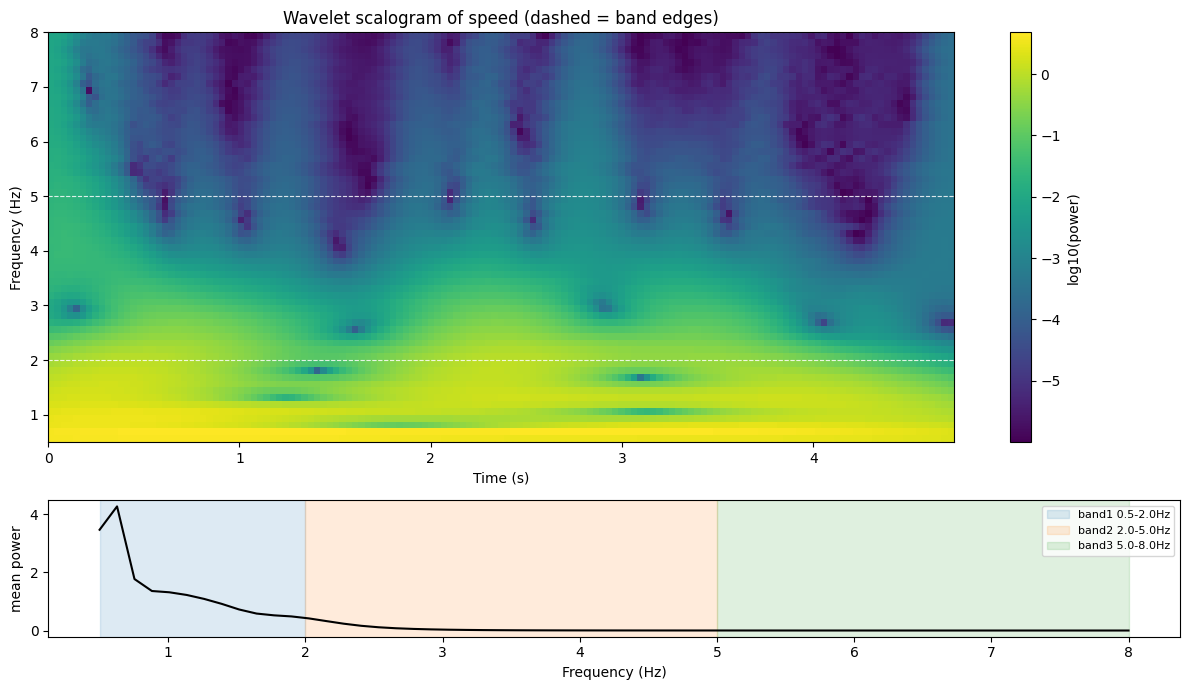

{'band1_dom_freq': 0.6271186440677966, 'band1_centroid': 0.9146233127691183, 'band1_band_power': 0.9194556297641885, 'band1_entropy': 2.236422534968635, 'band2_dom_freq': 2.0254237288135593, 'band2_centroid': 2.3617307916578096, 'band2_band_power': 0.07994137681957933, 'band2_entropy': 2.1356335616423108, 'band3_dom_freq': 5.076271186440678, 'band3_centroid': 5.98590729103482, 'band3_band_power': 0.0005901686610035032, 'band3_entropy': 2.9525230711684283}


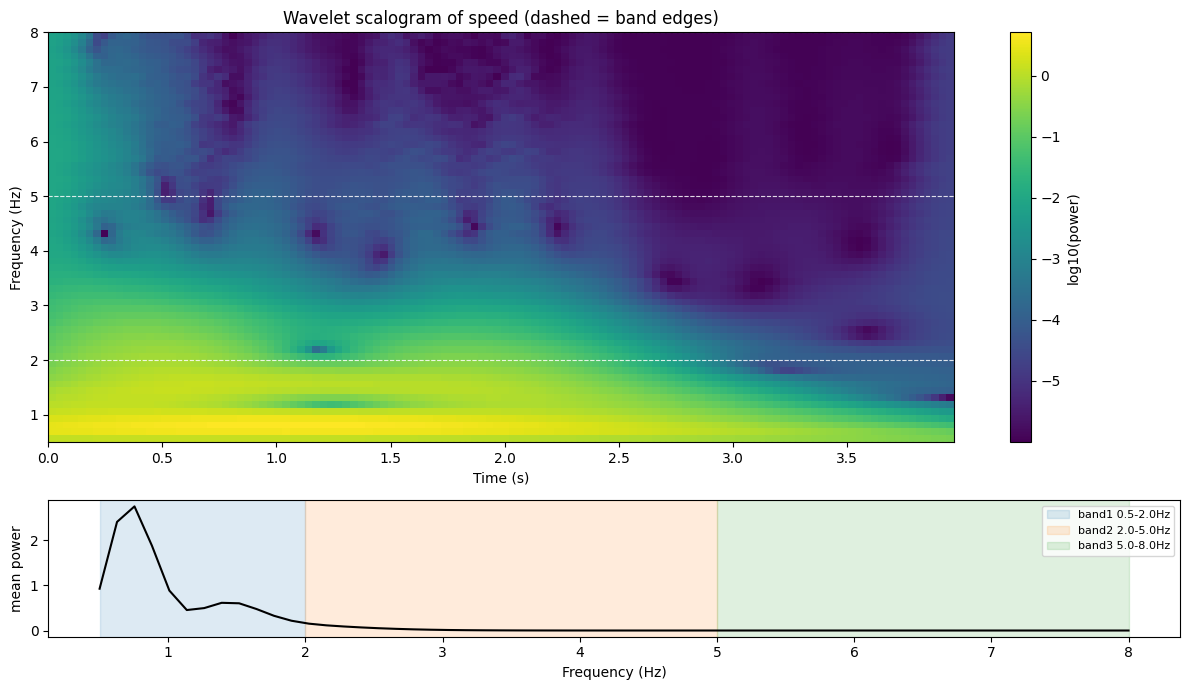

{'band1_dom_freq': 0.7542372881355932, 'band1_centroid': 0.937241166856679, 'band1_band_power': 0.9523881071838445, 'band1_entropy': 2.1935229308456607, 'band2_dom_freq': 2.0254237288135593, 'band2_centroid': 2.35754137884797, 'band2_band_power': 0.04697666629246565, 'band2_entropy': 2.1247790720276387, 'band3_dom_freq': 5.711864406779661, 'band3_centroid': 6.2367554878679465, 'band3_band_power': 0.0006197947925791966, 'band3_entropy': 3.086231721210344}


In [63]:
# 1.7  Wavelet rhythmicity (3 bands)   # KEEP (trimmed; still the richest rhythm feature)
def wavelet_rhythmicity(speed, time, bands=((0.5,2.0),(2.0,5.0),(5.0,8.0)),
                        n_freqs=60, fs=30, plot=False):
    out = {}
    speed = np.asarray(speed); time = np.asarray(time)
    if not HAVE_PYWT or (time[-1] - time[0]) < 0.7:
        for i,(a,b) in enumerate(bands):
            for k in ("dom_freq","centroid","band_power","entropy"):
                out[f"band{i+1}_{k}"] = np.nan
        return out
    dt = np.median(np.diff(time))
    freqs = np.linspace(min(b[0] for b in bands), max(b[1] for b in bands), n_freqs)
    scales = pywt.central_frequency("cmor1.5-1.0") * fs / freqs
    power = np.abs(pywt.cwt(speed, scales, "cmor1.5-1.0", sampling_period=dt)[0]) ** 2

    if plot:
        import matplotlib.pyplot as plt
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7),
                                       gridspec_kw={"height_ratios": [3, 1]}, sharex=False)
        # scalogram (time x frequency), log-scaled
        im = ax1.imshow(np.log10(power + 1e-6), aspect="auto", origin="lower",
                        extent=[time[0], time[-1], freqs[0], freqs[-1]], cmap="viridis")
        for (a, b) in bands:                       # mark band boundaries
            ax1.axhline(a, color="w", lw=0.8, ls="--", alpha=0.6)
            ax1.axhline(b, color="w", lw=0.8, ls="--", alpha=0.6)
        fig.colorbar(im, ax=ax1, label="log10(power)")
        ax1.set_ylabel("Frequency (Hz)"); ax1.set_xlabel("Time (s)")
        ax1.set_title("Wavelet scalogram of speed (dashed = band edges)")
        # mean power spectrum with bands shaded
        mp_plot = power.mean(axis=1)
        ax2.plot(freqs, mp_plot, color="k")
        for i, (a, b) in enumerate(bands):
            ax2.axvspan(a, b, alpha=0.15, color=f"C{i}", label=f"band{i+1} {a}-{b}Hz")
        ax2.set_xlabel("Frequency (Hz)"); ax2.set_ylabel("mean power"); ax2.legend(fontsize=8)
        plt.tight_layout(); plt.show()

    mp = power.mean(axis=1); mp /= (mp.sum() + 1e-12)
    for i,(a,b) in enumerate(bands):
        m = (freqs >= a) & (freqs < b); bf, bp = freqs[m], mp[m]
        if len(bp) == 0 or bp.sum() == 0:
            out[f"band{i+1}_dom_freq"]=out[f"band{i+1}_centroid"]=np.nan
            out[f"band{i+1}_band_power"]=0.0; out[f"band{i+1}_entropy"]=np.nan; continue
        p = bp / (bp.sum() + 1e-12)
        out[f"band{i+1}_dom_freq"]  = float(bf[np.argmax(bp)])
        out[f"band{i+1}_centroid"]  = float(np.sum(bf*bp)/np.sum(bp))
        out[f"band{i+1}_band_power"] = float(bp.sum())
        out[f"band{i+1}_entropy"]   = float(-np.sum(p*np.log(p+1e-12)))
    return out

print(wavelet_rhythmicity(sample_kin1['right_wrist_speed'], sample_kin1['time_s'], fs=sr1, plot=True))
print(wavelet_rhythmicity(sample_kin2['right_wrist_speed'], sample_kin2['time_s'], fs=sr2, plot=True))

In [64]:
# 1.8  Proximalization index (rel/abs)   # NEW  -- arm-level counterpart to the finger ratio
# wrist absolute speed includes elbow transport; wrist relspeed is elbow-removed articulation.
# ratio -> 0 : wrist just carried by the arm (proximalized).  ratio -> 1 : independent forearm
# rotation (distal). Mean over available arm joints that have a relspeed column.
def get_proximalization_index(df):
    ratios = []
    for side in SIDES:
        for j in ("wrist", "elbow"):
            ab, rel = f"{side}_{j}_speed", f"{side}_{j}_relspeed"
            if ab in df.columns and rel in df.columns:
                a = df[ab].to_numpy(); r = df[rel].to_numpy()
                denom = np.nanmedian(a)
                if denom > 1e-9:
                    ratios.append(np.nanmedian(r) / denom)
    return np.nanmean(ratios) if ratios else np.nan

print(get_proximalization_index(sample_kin1))
print(get_proximalization_index(sample_kin2))


0.7505159769423924
1.0266483604393912


## 2 · Hand / handshape features  (`*_hand_distances.csv` + finger cols of kinematics)

Handshape geometry, finger independence, and distal articulation. **Key fix:** finger
independence and distal-proximal are computed on **gross-independent** signals (distance
columns / tip-relative-to-MCP), *not* absolute fingertip speed — the latter is ~0.8
correlated with wrist motion, so it measures transport, not finger control.


In [65]:
# 2.1  Handshape geometry from distance columns   # KEEP, ported to numeric dist cols
def feature_adjacent_fingertip_spread(df, side):
    """Mean & std of adjacent fingertip gaps (thumb-index, index-middle, ...)."""
    cols = [dist_col(side, 4, 8), dist_col(side, 8, 12),
            dist_col(side, 12, 16), dist_col(side, 16, 20)]
    cols = [c for c in cols if c in df.columns]
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

def feature_thumb_index_distance(df, side):                # aperture / pinch
    c = dist_col(side, 4, 8)
    return (df[c].mean(), df[c].std()) if c in df.columns else (np.nan, np.nan)

def feature_mcp_tip_distance(df, side):                     # overall flexion (tip->MCP)
    cols = [dist_col(side, FINGER_TIP_ID[f], FINGER_MCP_ID[f])
            for f in ["thumb","index","middle","ring","pinky"]]
    cols = [c for c in cols if c in df.columns]
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

# NEW: thumb opposition — thumb tip to pinky MCP (a distinct phonological handshape axis)
def feature_thumb_opposition(df, side):
    c = dist_col(side, 4, FINGER_MCP_ID["pinky"])           # r4_17
    return (df[c].mean(), df[c].std()) if c in df.columns else (np.nan, np.nan)

# spread
print(feature_adjacent_fingertip_spread(sample_dist1, "right"))
print(feature_adjacent_fingertip_spread(sample_dist2, "right"))

# thumb-index distance
print(feature_thumb_index_distance(sample_dist1, "right"))
print(feature_thumb_index_distance(sample_dist2, "right"))

# mcp-tip distance
print(feature_mcp_tip_distance(sample_dist1, "right"))
print(feature_mcp_tip_distance(sample_dist2, "right"))

# thumb opposition
print(feature_thumb_opposition(sample_dist1, "right"))
print(feature_thumb_opposition(sample_dist2, "right"))

(0.5048154548984572, 0.19657274624848997)
(1.0351736387080717, 0.43178428586762296)
(0.788639984984575, 0.48350163717173905)
(1.598669357714077, 0.6238947739492059)
(1.0625774464749411, 0.1501563051966416)
(1.9770988162529217, 0.5297526771844618)
(1.7457688367172848, 0.27045368610782294)
(2.9820161359059587, 0.5487910879083462)


In [ ]:
# 2.2  Handshape size & variability   # KEEP, ported
def feature_handshape_size(df, side):
    p = "r" if side == "right" else "l"
    cols = [c for c in df.columns
            if c.startswith(p) and "_" in c
            and not c.endswith(("_x","_y","_speed","_acc","_jerk"))
            and df[c].dtype != object]
    if not cols: return np.nan, np.nan
    return df[cols].mean(axis=1).mean(), df[cols].std(axis=1).mean()

def feature_handshape_variability(df, side):
    """Total temporal SD of the adjacent-fingertip gaps = how much handshape changes."""
    cols = [dist_col(side, 4, 8), dist_col(side, 8, 12),
            dist_col(side, 12, 16), dist_col(side, 16, 20)]
    cols = [c for c in cols if c in df.columns]
    return df[cols].std().sum() if cols else np.nan

# handshape size
print("handshape size")
print(feature_handshape_size(sample_dist1, "right"))
print(feature_handshape_size(sample_dist2, "right"))

# handshape variability
print("handshape variability")
print(feature_handshape_variability(sample_dist1, "right"))
print(feature_handshape_variability(sample_dist2, "right"))


handshape size
(5.553572068576557, 10.674141951239658)
(6.406650059953085, 15.549440361437341)
handshape variability
1.119664366666655
2.142825952902557


In [67]:
# 2.3  Fingertip dynamics — GROSS-INDEPENDENT versions   # FIX
# Old code used <side>_INDEX_FINGER_TIP_speed (absolute, MediaPipe name -> all NaN on Sapiens,
# and conceptually wrist-contaminated). Use the tip->MCP distance speed columns instead:
# r8_5_speed etc. = rate of the tip-to-its-own-MCP distance = finger flexion speed, transport-free.
def _tip_mcp_speed_cols(df, side):
    cols = [f"{dist_col(side, FINGER_TIP_ID[f], FINGER_MCP_ID[f])}_speed"
            for f in ["index","middle","ring","pinky"]]     # thumb handled separately
    return [c for c in cols if c in df.columns]

def feature_fingertip_speed(df, side):                      # FIX: transport-free
    cols = _tip_mcp_speed_cols(df, side)
    if not cols: return np.nan, np.nan
    return df[cols].mean().mean(), df[cols].mean().std()

def feature_fingertip_jerk(df, side):                       # FIX: transport-free
    cols = [c.replace("_speed", "_jerk") for c in _tip_mcp_speed_cols(df, side)]
    cols = [c for c in cols if c in df.columns]
    return df[cols].mean().mean() if cols else np.nan

print("fingertip speed")
print(feature_fingertip_speed(sample_dist1, "right"))
print(feature_fingertip_speed(sample_dist2, "right"))

print("fingertip jerk")
print(feature_fingertip_jerk(sample_dist1, "right"))
print(feature_fingertip_jerk(sample_dist2, "right"))

fingertip speed
(1.3414553538645329, 0.14441469082567054)
(2.305640770462585, 0.24977141911922052)
fingertip jerk
-2.617639170008474
5.668087607140037


In [68]:
# 2.4  Finger independence   # FIX (was on absolute tip speed -> measured shared transport)
# Correlate FLEXION speeds (tip->MCP distance speed), which have wrist motion removed.
# independence = 1 - mean pairwise corr.  High = fingers move independently (native-signer-like).
def feature_finger_independence(df, side):
    pairs = [("index","middle"), ("middle","ring"), ("ring","pinky")]
    corrs = []
    for a, b in pairs:
        ca = f"{dist_col(side, FINGER_TIP_ID[a], FINGER_MCP_ID[a])}_speed"
        cb = f"{dist_col(side, FINGER_TIP_ID[b], FINGER_MCP_ID[b])}_speed"
        if ca in df.columns and cb in df.columns:
            corrs.append(df[ca].corr(df[cb]))
    return 1 - np.nanmean(corrs) if corrs else np.nan

def feature_finger_speed_correlation(df, side, f1="index", f2="middle"):  # FIX: flexion-based
    ca = f"{dist_col(side, FINGER_TIP_ID[f1], FINGER_MCP_ID[f1])}_speed"
    cb = f"{dist_col(side, FINGER_TIP_ID[f2], FINGER_MCP_ID[f2])}_speed"
    if ca in df.columns and cb in df.columns:
        return df[ca].corr(df[cb])
    return np.nan

print("finger indepenedence")
print(feature_finger_independence(sample_dist1, "right"))
print(feature_finger_independence(sample_dist2, "right"))

print("finger speed correlation")
print(feature_finger_speed_correlation(sample_dist1, "right"))
print(feature_finger_speed_correlation(sample_dist2, "right"))

finger indepenedence
0.15094077555764995
0.12736945205958472
finger speed correlation
0.809712349760017
0.7091644224819295


In [69]:
# 2.5  Distal-proximal ratio (finger-level proximalization)   # FIX
# Old: absolute tip speed / absolute MCP speed under MediaPipe names (NaN + transport-biased).
# New: flexion (tip->MCP distance speed) vs. MCP-in-hand motion. High = distal-led.
def feature_distal_proximal_ratio(df_kin, df_dist, side):
    distal = _tip_mcp_speed_cols(df_dist, side)                  # flexion speed (distal articulation)
    # proximal reference: MCP keypoint speed in the palm frame, from the kinematics file
    prox = [f"{kp(side, mcp_stem(f))}_speed" for f in ["index","middle"]]
    prox = [c for c in prox if c in df_kin.columns]
    distal = [c for c in distal if c in df_dist.columns]
    if not distal or not prox: return np.nan
    return np.nanmean(df_dist[distal].mean(axis=1) / df_kin[prox].mean(axis=1))

print(feature_distal_proximal_ratio(sample_kin1, sample_dist1, "right"))
print(feature_distal_proximal_ratio(sample_kin2, sample_dist2, "right"))

0.4886909556186375
1.340141141333336


In [70]:
# 2.6  Speed entropy of finger flexion (variability of the signal)   # KEEP, ported
def feature_finger_speed_entropy(df, side, finger="index"):
    c = f"{dist_col(side, FINGER_TIP_ID[finger], FINGER_MCP_ID[finger])}_speed"
    if c not in df.columns: return np.nan
    hist, _ = np.histogram(df[c].dropna(), bins=30, density=True)
    return entropy(hist + 1e-8)

print(feature_finger_speed_entropy(sample_dist1, "right"))
print(feature_finger_speed_entropy(sample_dist2, "right"))

3.1381879883958805
2.2097272568763615


## 3 · Per-file assembly

`extract_gross_features` (§1) and `extract_hand_features` (§2) each return a flat dict;
`extract_all` merges them for one file. Ordering mirrors the sections: gross first, hand second.


In [ ]:
def _mean_sides(fn, *dfs):
    """Call fn(*dfs, side) for each side, return nan-mean of the (scalar or tuple) results.
    Handles fns that return a scalar OR a (mean, std) tuple -> returns pooled scalar/tuple."""
    vals = [fn(*dfs, side) for side in SIDES]
    if isinstance(vals[0], tuple):
        return tuple(np.nanmean([v[i] for v in vals]) for i in range(len(vals[0])))
    return np.nanmean(vals)


def fname(name: str, domain: str, family: str) -> str:
    """Format a feature column name as domain__family__name."""
    return f"{domain}__{family}__{name}"

def extract_gross_features(df, fs):
    f = {}
    # aggregate arm-speed descriptives (uses your total_arm_* columns)
    for col, tag in [(TOTAL_ARM_SPEED, "arm_speed"), (TOTAL_ARM_ACC, "arm_acc")]:
        if col in df.columns:
            f[fname(f"{tag}_Gmean", "gross", "magnitude")]   = df[col].mean()
            f[fname(f"{tag}_Gstd",  "gross", "variability")] = df[col].std()
            pk = compute_peaks(df, col, fs)
            f[fname(f"{tag}_peak_mean", "gross", "magnitude")]   = pk["peak_mean"]
            f[fname(f"{tag}_peak_std",  "gross", "variability")] = pk["peak_std"]
            f[fname(f"{tag}_peak_n",    "gross", "rhythm")]      = pk["peak_n"]
            f[fname(f"{tag}_peak_rate", "gross", "rhythm")]      = pk["peak_rate"]
            f[fname(f"{tag}_mod_depth", "gross", "rhythm")]      = pk["mod_depth"]
    # integral / smoothness / rhythm on the (already bilateral) total_arm signal
    if TOTAL_ARM_SPEED in df.columns:
        f[fname("arm_speed_integral", "gross", "magnitude")] = np.trapz(df[TOTAL_ARM_SPEED].values, dx=1/fs)
        if HAVE_ANTROPY:
            f[fname("arm_speed_sampen", "gross", "rhythm")] = ent.sample_entropy(df[TOTAL_ARM_SPEED].values, order=2)
        f[fname("arm_intermittency", "gross", "smoothness")] = get_intermittency(
            df.get(TOTAL_ARM_JERK, pd.Series(dtype=float)), df[TOTAL_ARM_SPEED])
        f[fname("arm_sparc", "gross", "smoothness")] = get_sparc(df[TOTAL_ARM_SPEED].values, fs)
        for k, v in wavelet_rhythmicity(df[TOTAL_ARM_SPEED], df[TIME_COL], fs=fs).items():
            f[fname(f"{k}_totalarm", "gross", "rhythm")] = v

    # BBMV: ONE value = sum over shoulders + elbows + wrists, both sides   # CHANGED
    bbmv_total = np.nansum([get_bbmv(df, side, j) for side in SIDES for j in ARM_JOINTS])
    f[fname("bbmv_arms_total", "gross", "magnitude")] = bbmv_total

    # directness: pooled across sides/joints into one value   # CHANGED (mean over L/R)
    dvals = [get_path_directness(df, side, j) for side in SIDES for j in ARM_JOINTS]
    f[fname("directness_arms", "gross", "proxdist")] = np.nanmean(dvals)

    # coordination — intrinsically bilateral, computed once (NOT side-averaged)
    f[fname("arm_coupling",  "gross", "coordination")] = compute_arm_coupling(df)
    f[fname("arm_asymmetry", "gross", "coordination")] = compute_arm_asymmetry(df)
    f[fname("proximalization_index", "gross", "proxdist")] = get_proximalization_index(df)  # already means over sides internally
    return f


def extract_hand_features(df_kin, df_dist):
    f = {}
    # --- geometry / handshape: mean over L and R ---
    m, sd = _mean_sides(feature_adjacent_fingertip_spread, df_dist)
    f[fname("fingertip_spread_mean", "fine", "handshape")]   = m
    f[fname("fingertip_spread_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_thumb_index_distance, df_dist)
    f[fname("thumb_index_mean", "fine", "handshape")]   = m
    f[fname("thumb_index_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_mcp_tip_distance, df_dist)
    f[fname("mcp_tip_mean", "fine", "handshape")]   = m
    f[fname("mcp_tip_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_thumb_opposition, df_dist)
    f[fname("thumb_opposition_mean", "fine", "handshape")]   = m
    f[fname("thumb_opposition_std",  "fine", "variability")] = sd

    m, sd = _mean_sides(feature_handshape_size, df_dist)
    f[fname("handshape_size_mean", "fine", "handshape")]   = m
    f[fname("handshape_size_std",  "fine", "variability")] = sd

    f[fname("handshape_variability", "fine", "variability")] = np.nanmean(
        [feature_handshape_variability(df_dist, side) for side in SIDES])

    # --- dynamics (gross-independent): mean over L and R ---
    m, sd = _mean_sides(feature_fingertip_speed, df_dist)
    f[fname("flexion_speed_mean", "fine", "magnitude")]   = m
    f[fname("flexion_speed_std",  "fine", "variability")] = sd

    f[fname("flexion_jerk", "fine", "smoothness")] = np.nanmean(
        [feature_fingertip_jerk(df_dist, side) for side in SIDES])

    # coordination — average the two hands' independence/correlations (each is within-hand,
    # so a mean of the two hands is meaningful here, unlike arm L<->R coupling)
    f[fname("finger_independence", "fine", "coordination")] = np.nanmean(
        [feature_finger_independence(df_dist, side) for side in SIDES])
    for a, b in [("index", "middle"), ("middle", "ring"), ("ring", "pinky")]:
        f[fname(f"corr_{a}_{b}", "fine", "coordination")] = np.nanmean(
            [feature_finger_speed_correlation(df_dist, side, a, b) for side in SIDES])

    f[fname("distal_proximal_ratio", "fine", "proxdist")] = np.nanmean(
        [feature_distal_proximal_ratio(df_kin, df_dist, side) for side in SIDES]) #THIS ONE IS PROBABLY UNNECESSARY
    f[fname("flexion_entropy", "fine", "variability")] = np.nanmean(
        [feature_finger_speed_entropy(df_dist, side, "index") for side in SIDES])
    return f


def extract_all(df_kin, df_dist, fs):
    return {**extract_gross_features(df_kin, fs), **extract_hand_features(df_kin, df_dist)}

**Note on `distal_proximal_ratio`:** it needs the MCP *keypoint* speed (e.g.
`right_forefinger_third_joint_speed`) which lives in the **kinematics** file, while the flexion
speed lives in the **distances** file. If you keep them in separate files, either (a) merge the
MCP-speed columns into `df_dist` before this call, or (b) pass `df_kin` into the function. The
stub above reads from `df_dist`; adjust to your merged layout.

## 4 · Batch loop

Preserves your fileID → group / concept parsing. Set the two glob paths, then run.


In [120]:
processedfolder = os.path.join(curfolder, "Sapiens_Processed")   # <-- set curfolder above
datasetsfolder  = os.path.join(curfolder, "Datasets")

kin_files = sorted(glob.glob(os.path.join(processedfolder, "*_kinematics.csv")))

rows = []
for kin_file in kin_files:
    print("processing", os.path.basename(kin_file))

    dist_file = kin_file.replace("_kinematics.csv", "_hand_distances.csv")
    if not os.path.exists(dist_file):
        print("no distance file for", os.path.basename(kin_file)); continue

    df_kin  = pd.read_csv(kin_file)
    df_dist = pd.read_csv(dist_file)
    fid = df_kin["FileID"].iloc[0]
    #break

    # skip practice trials
    # if any(t in fid for t in ("LIGHTNING", "TO-HEAR", "GOAL")):
    #     continue

    fs = round(len(df_kin) / (df_kin[TIME_COL].iloc[-1] - df_kin[TIME_COL].iloc[0]))

    feats = extract_all(df_kin, df_dist, fs)
    feats["fileID"] = fid

    # ---- group parsing (KEEP from original) ----
    if "GtST" in fid:
        feats["group"] = fid.split("_")[0]
        feats["groupID"] = 'Sign'
    elif 'GP' in fid:
        feats["group"] = fid.split("_")[0]
        feats["groupID"] = 'Gesture'
    elif fid.startswith("LP") or fid.startswith("IP"):
        feats["group"] = "_".join(fid.split("_")[:2])
        if "_01_" in fid:
            feats["groupID"] = 'Learner_1'
        elif "_02_" in fid:
            feats["groupID"] = 'Learner_2'
        else:
            print('error')
            break

    elif "ViCom" in fid:
        feats["group"] = "ViCom"
        feats["groupID"] = "Sign"
    else:
        print("unparsed fileID:", fid); continue

    # ---- concept parsing (KEEP) ----
    try:
        if "GtST" in fid:   feats["concept"] = fid.split("_")[2].split(".")[0]
        elif "GP" in fid:   feats["concept"] = fid.split("_")[1].split(".")[0]
        elif "LP" in fid or "IP" in fid: feats["concept"] = fid.split("_")[2].split(".")[0]
        elif "ViCom" in fid: feats["concept"] = fid.split("_")[3].split(".")[0]
    except IndexError:
        feats["concept"] = np.nan
    fix = {"TO-PICK":"TO-PLUCK", "TO-MOVE-HOUSES":"TO-MOVE", "VIDEO-GAME":"VIDEOGAME"}
    feats["concept"] = fix.get(feats.get("concept"), feats.get("concept"))

    rows.append(feats)

    #feats["groupID"] = fid[:2]

    #break

features_df = pd.DataFrame(rows)
print(features_df.shape, "->", features_df["group"].value_counts().to_dict() if len(features_df) else "empty")

features_df['pcnID'] = features_df['group'].str.split("_").str[0]

features_df.to_csv(os.path.join(datasetsfolder, "sapiens_features.csv"), index=False)

processing GP01_ADLER_kinematics.csv
processing GP01_ANSTECKEN_kinematics.csv
processing GP01_BLITZ_kinematics.csv
processing GP01_BODEN_kinematics.csv
processing GP01_BRIEF_kinematics.csv
processing GP01_BUERO_kinematics.csv
processing GP01_ENTSCHULDIGEN_kinematics.csv
processing GP01_GEIGE_kinematics.csv
processing GP01_GIRAFFE_kinematics.csv
processing GP01_GOTT_kinematics.csv
processing GP01_HEMD_kinematics.csv
processing GP01_KLOPFEN_kinematics.csv
processing GP01_MENSCH_kinematics.csv
processing GP01_RUFEN_kinematics.csv
processing GP01_SCHOKOLADE_kinematics.csv
processing GP01_STAUBSAUGEN_kinematics.csv
processing GP01_WENIG_kinematics.csv
processing GP02_ABLEHNEN_kinematics.csv
processing GP02_ANTWORTEN_kinematics.csv
processing GP02_FENSTER_kinematics.csv
processing GP02_GEHOERLOS_kinematics.csv
processing GP02_GITARRE_kinematics.csv
processing GP02_GUT_kinematics.csv
processing GP02_IGNORIEREN_kinematics.csv
processing GP02_MUSIK_kinematics.csv
processing GP02_PARKEN_kinemati

In [121]:
features_df_clean = features_df[~features_df['group'].str.startswith('LP')]
features_df_clean.to_csv(os.path.join(datasetsfolder, "sapiens_features_noLP.csv"), index=False)

In [122]:
noconcept = pd.read_csv('sampled_files_noconcept.csv', index_col=0)
noconcept['filename'] = noconcept['file'].replace(" .mp4", "", regex=True)
noconcept['filename'] = noconcept['file'].replace(".mp4", "", regex=True)

# in features_df, keep only those that are in noconcept, matching fileID and filename
features_df_NC = features_df[features_df['fileID'].isin(noconcept['filename'])]
features_df_NC

features_df_NC_clean = features_df_NC[~features_df_NC['group'].str.startswith('LP')]
features_df_NC_clean.to_csv(os.path.join(datasetsfolder, "sapiens_features_noconcept_noLP.csv"), index=False)

In [124]:
features_df_NC_clean

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__coordination__corr_index_middle,fine__coordination__corr_middle_ring,fine__coordination__corr_ring_pinky,fine__proxdist__distal_proximal_ratio,fine__variability__flexion_entropy,fileID,group,groupID,concept,pcnID
1,0.552371,0.486426,1.377468,0.542730,4,0.851064,1.030222,2.064245,1.947847,4.349243,...,0.463926,0.726656,0.426655,0.975861,3.073719,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN,GP01
3,1.053819,0.653684,2.200471,0.711201,4,0.845070,1.443957,3.122254,2.348642,6.000079,...,0.978735,0.923227,0.760044,0.850163,2.952784,GP01_BODEN,GP01,Gesture,BODEN,GP01
4,0.954794,0.768327,2.031465,1.121333,4,0.851064,1.835851,3.638679,2.860333,5.610632,...,0.671586,0.818125,0.855292,1.019093,3.166920,GP01_BRIEF,GP01,Gesture,BRIEF,GP01
5,0.385791,0.478493,1.225327,0.688305,3,0.638298,1.045060,1.589367,1.799295,4.567698,...,0.919347,0.959597,0.856491,1.034595,2.484640,GP01_BUERO,GP01,Gesture,BUERO,GP01
6,0.475486,0.705323,2.406980,NaN,1,0.212766,NaN,1.934251,2.938965,3.545241,...,0.945602,0.957496,0.925923,0.908041,2.567418,GP01_ENTSCHULDIGEN,GP01,Gesture,ENTSCHULDIGEN,GP01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1355,0.848801,0.758336,2.178872,0.700623,2,0.714286,2.154066,3.138886,2.230948,6.173794,...,0.884970,0.850191,0.812310,0.944186,2.863653,ViCom_98_F_BAPTISM,ViCom,Sign,BAPTISM,ViCom
1356,1.064878,0.848263,2.707430,0.065215,2,0.909091,2.633038,4.751467,3.200436,8.398743,...,0.904239,0.935377,0.950051,0.797826,3.093587,ViCom_98_P_TABLE,ViCom,Sign,TABLE,ViCom
1357,1.171158,0.781078,1.840424,1.164542,4,1.463415,1.297601,3.909935,3.096893,7.385713,...,0.967153,0.988118,0.913262,0.835899,3.131641,ViCom_99_F_BIRD,ViCom,Sign,BIRD,ViCom
1358,0.791466,0.810907,2.451725,0.135782,2,0.666667,2.432833,3.663859,2.859393,8.466912,...,0.859105,0.892026,0.780848,27.615500,2.864223,ViCom_99_P_TO-HEAR,ViCom,Sign,TO-HEAR,ViCom


## 5 · Quick QC — did anything silently NaN?

The recurring failure mode in this pipeline is a name mismatch returning all-NaN. Run this
right after extraction: any feature at ~100 % NaN is almost certainly a config-name problem
(fix in §0), **not** missing data.


In [117]:
nan_pct = features_df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("features >50% NaN (check names in §0):")
print(nan_pct[nan_pct > 50])

features >50% NaN (check names in §0):
Series([], dtype: float64)


In [118]:
import plotly.express as px, pandas as pd, umap
from sklearn.preprocessing import StandardScaler

feat_df = features_df_clean.copy()

meta_cols = ['fileID', 'group', 'concept', 'groupID']        # add 'groupID' only if it exists
meta_cols = [c for c in meta_cols if c in feat_df.columns]

num = feat_df.select_dtypes('number')

# drop feature columns that are entirely/mostly NaN FIRST, so dropna(rows) doesn't nuke everything
num = num.loc[:, num.isna().mean() < 0.5]         # keep cols <50% NaN

# now drop rows with any remaining NaN, and carry the SAME index through to metadata
keep = num.dropna().index                          # surviving row labels
num  = num.loc[keep]
meta = feat_df.loc[keep, meta_cols]               # <-- same rows, stays aligned

scaled   = StandardScaler().fit_transform(num)
embedding = umap.UMAP(random_state=42).fit_transform(scaled)

plot_df = pd.DataFrame(embedding, columns=['x', 'y'], index=keep)
plot_df = pd.concat([plot_df, meta], axis=1)       # aligned by index, not by position

fig = px.scatter(plot_df, x='x', y='y',
                 color='groupID' if 'groupID' not in plot_df else 'groupID',
                 symbol='group', hover_name='concept',
                 title='UMAP projection', opacity=0.6)
fig.update_layout(width=900, height=800, yaxis=dict(scaleanchor='x', scaleratio=1))
fig.show()